# 06 · Drift monitoring and serving — after deployment

Logic: `src/monitoring.py`, `src/drift_data.py`, `scripts/simulate_drift.py`, `scripts/retrain_if_drift.py`, `src/api/`.
Background: EXPERIMENTS E8–E9, decisions W1–W9 and A1–A8, deviations DV-004 and DV-005.

**The problem:** a deployed model keeps answering even when the incoming data no longer looks like its training data —
it just answers badly. Drift monitoring compares new sensor readings with the training readings, per sensor:
- **KS test**: "is there a difference?" (p-value). With thousands of readings it flags even tiny, harmless differences.
- **PSI**: "how big is the difference?" Cut the training readings into 10 equal-count bins and compare the share of new
  readings per bin. < 0.1 stable, 0.1–0.2 moderate, > 0.2 large.
- **Rule:** a sensor drifts if KS p < 0.05 **and** PSI > 0.2; **alarm** if ≥ 3 sensors drift.

Batches compared with the FD001 training engines: FD001 validation engines (**no-drift control**), FD001 test engines
(stopped before failure), FD002 test engines (**six operating conditions** instead of one).

In [1]:
import sys, pathlib, warnings
ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / "src").exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from src import config
from src.plotting import apply_style, save_fig
apply_style()
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
RESULTS = ROOT / "results"
from src.plotting import plot_psi_by_sensor, plot_drift_distributions
summary = pd.read_csv(RESULTS / "drift_summary.csv")
report = pd.read_csv(RESULTS / "drift_report.csv")
impact = pd.read_csv(RESULTS / "drift_model_impact.csv")
summary[["batch", "n_ks_drift", "n_psi_drift", "n_drift", "median_psi", "max_psi", "alarm"]].round(3)

,batch,n_ks_drift,n_psi_drift,n_drift,median_psi,max_psi,alarm
0,FD001-val,5.00,0.00,0.00,0.005,0.046,False
1,FD001-test,14.00,11.00,11.00,0.270,0.350,True
2,FD002-test,14.00,14.00,14.00,3.000,3.246,True
3,"FD001-val cut off like test, vs reference (20 ...",14.00,6.25,6.25,0.199,0.608,14/20
4,"FD001-val cut off like test, vs FD001-test (20...",12.95,0.00,0.00,0.017,0.161,0/20


## 1 · Detection results
**What the table tells us:** the control is quiet (KS alone would have flagged 5 sensors — the PSI requirement prevents
a false alarm). FD002 alarms massively (median PSI 3.0). FD001 test also alarms, and the last two rows show why: cutting
the control engines off the way the test engines were cut reproduces the shift, and then they match the test engines.
The test engines are mostly healthy, early-life readings — a real change in the data, but not a harmful one.

> **How to read this figure:** PSI per sensor (log scale). Right of the dashed line (0.2) = large shift; a dot = KS also
> significant, so the sensor counts toward the alarm.

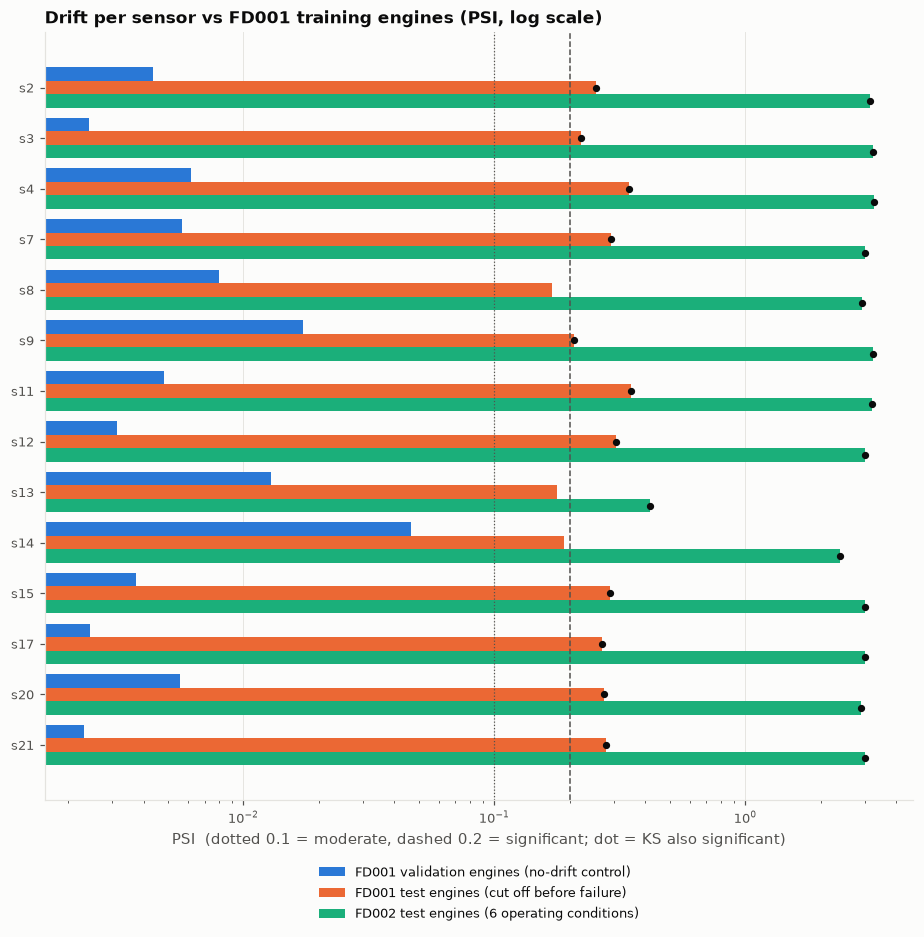

In [2]:
fig = plot_psi_by_sensor(report); plt.show()

## 2 · What the shift looks like
> **How to read this figure:** distributions of four sensors (raw units). Grey = FD001 training engines. Top row: FD001
> batches; bottom row: FD002 on its full range.

**What it tells us:** the control (blue) lies on the reference; the cut-off test engines (orange) lean to lower, healthy
values. FD002 splits into six clusters, one per operating condition — only one overlaps the narrow FD001 band.

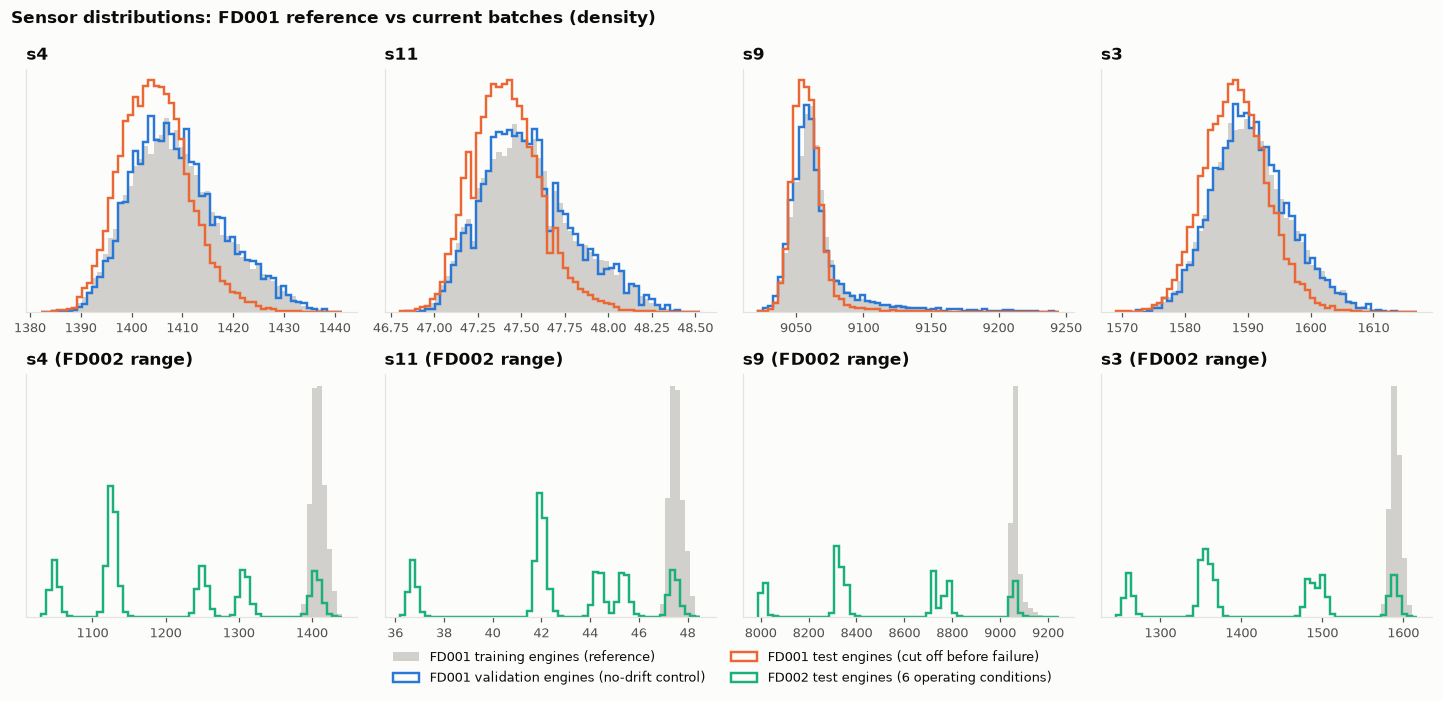

In [3]:
from src.drift_data import BATCHES, current_batch, reference_frame
ref = reference_frame("FD001")
fig = plot_drift_distributions(ref, {b: current_batch(b) for b in BATCHES}, ["s4", "s11", "s9", "s3"]); plt.show()

## 3 · Does drift hurt the models?
FD001-trained models scored on FD002 through their own FD001 scaler, then the model retrained after the alarm
(`xgboost_retrained`, FD001 + FD002 training engines). RMSE in cycles; `clip125` = against truth capped at 125
(57 of the 259 FD002 test engines have true RUL > 125, so even a perfect capped model scores 18.3 unclipped).

**What it tells us:** the best FD001 model scores **63.6 on FD002 — worse than always predicting 86.6 (54.1)**.
Retraining brings XGBoost from 48.1 to **30.4** (37.2 → **18.3** capped) while staying ~18 on FD001.

In [4]:
import json
from src.registry import get_latest
row = get_latest("xgboost_retrained")
meta = json.loads((ROOT / row["path"] / "metadata.json").read_text())
after = meta["retrain"]["test_metrics_by_subset"]
retr = pd.DataFrame([{"model": "xgboost_retrained", "test_set": s, "test_rmse": m["rmse"],
                      "test_rmse_clip125": m["rmse_clip125"]} for s, m in after.items()])
pd.concat([impact[["model", "test_set", "test_rmse", "test_rmse_clip125", "nasa_per_engine"]], retr]).round(2)

,model,test_set,test_rmse,test_rmse_clip125,nasa_per_engine
0,xgboost_tuned,FD001,17.76,16.50,6.71
1,xgboost_tuned,FD002,48.13,37.25,266.14
2,lstm_uni_tuned,FD001,14.25,12.91,3.21
3,lstm_uni_tuned,FD002,63.65,59.75,8014.56
0,xgboost_retrained,FD001,18.24,17.02,NaN
1,xgboost_retrained,FD002,30.39,18.31,NaN


## 4 · The retraining job's decisions
`scripts/retrain_if_drift.py` (meant to run on a schedule): no alarm → nothing; alarm on the reference's own subset →
flag for human review (no new regime to learn from); alarm on a new regime → retrain, register (`retrained_after_drift`),
and store the new regime's training engines as the new reference, so the next run doesn't retrain again. Below, only
the detection step, against both references (nothing is retrained or registered).

**What the table tells us:** against the FD001 reference, FD002 alarms; against the retrained model's FD002 reference,
FD002 is quiet (median PSI 0.014), so the job does not retrain again. **Limit:** FD001 batches now alarm against the FD002
reference (PSI ≈ 6.9). Using the new regime as the reference assumes the fleet has moved to it entirely. A fleet mixing
both regimes would need a pooled reference *and* pooled batches, or monitoring per operating condition (future work,
DECISIONS W8).

In [5]:
from src.config import SENSORS
from src.monitoring import compute_feature_drift, drift_summary, load_reference
ref_fd001, _ = load_reference(ROOT / "trained_models" / "reference_FD001.npz")
ref_new, meta_new = load_reference(ROOT / row["path"] / "reference.npz")
rows = []
for name, r in [("FD001 reference", ref_fd001), (f"retrained model's reference ({meta_new['subset']})", ref_new)]:
    for b in BATCHES:
        s = drift_summary(compute_feature_drift(r, current_batch(b), SENSORS))
        rows.append({"reference": name, "batch": b, "drifting sensors": s["n_drift"],
                     "median PSI": round(s["median_psi"], 3), "alarm": s["alarm"]})
pd.DataFrame(rows)

,reference,batch,drifting sensors,median PSI,alarm
0,FD001 reference,FD001-val,0,0.005,False
1,FD001 reference,FD001-test,11,0.271,True
2,FD001 reference,FD002-test,14,3.001,True
3,retrained model's reference (FD002),FD001-val,14,6.885,True
4,retrained model's reference (FD002),FD001-test,14,6.865,True
5,retrained model's reference (FD002),FD002-test,0,0.014,False


## 5 · Serving: the API reproduces the official predictions
The API (`src/api/`) takes an engine's raw readings (24 values per cycle) and runs the training pipeline itself. Here it
runs in-process (`fastapi.testclient`) on all 100 FD001 test engines, and every prediction is compared with the
comparison script's. The same check was run against the Docker container (EXPERIMENTS E9). To use the real service:
`docker run --rm -p 8000:8000 pm-api`, then open `http://localhost:8000/docs`.

In [6]:
from fastapi.testclient import TestClient
from src.api.main import create_app
from src.data_loader import load_cmapss
expected = pd.read_csv(RESULTS / "test_predictions_all_models.csv").set_index("unit_id")
test_raw = load_cmapss("FD001", "test")
diffs = []
with TestClient(create_app()) as c:
    print(c.get("/health").json())
    for u, g in test_raw.groupby("unit_id"):
        out = c.post("/predict/compare", json={"readings": g.sort_values("cycle")[config.RAW_FEATURE_COLS].values.tolist()})
        diffs += [abs(p["predicted_rul"] - expected.loc[u, p["model_name"]]) for p in out.json()["predictions"]]
    example = c.post("/predict", json={"unit_id": "76", "readings":
                     test_raw[test_raw.unit_id == 76].sort_values("cycle")[config.RAW_FEATURE_COLS].values.tolist()}).json()
print(f"{len(diffs)} predictions, largest difference {max(diffs):.4f} cycles")
example

{'status': 'ok', 'model_loaded': True, 'models': ['lstm_uni_tuned', 'tcn_tuned', 'xgboost_tuned'], 'default_model': 'lstm_uni_tuned'}


300 predictions, largest difference 0.0005 cycles


{'predicted_rul': 8.047903060913086,
 'model_name': 'lstm_uni_tuned',
 'model_version': '1',
 'timestamp': '2026-11-02T17:29:01+00:00',
 'unit_id': '76',
 'input_cycles': 205,
 'padded': False,
 'latency_ms': 11.257400001341011}